In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
egitim = pd.read_csv('egitim.csv')
test = pd.read_csv('test.csv')

In [3]:
x_train = egitim.iloc[:, 0].values
y_train = egitim.iloc[:, 1].values

x_test = test.iloc[:, 0].values
y_test = test.iloc[:, 1].values

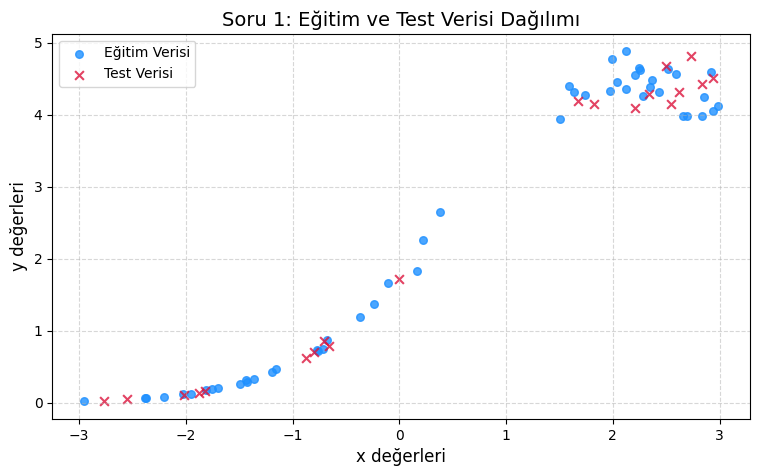

In [4]:
plt.figure(figsize=(9, 5))
plt.scatter(x_train, y_train, color='dodgerblue', label='Eğitim Verisi', alpha=0.8, s=30)
plt.scatter(x_test, y_test, color='crimson', label='Test Verisi', alpha=0.8, marker='x', s=40)
plt.xlabel('x değerleri', fontsize=12)
plt.ylabel('y değerleri', fontsize=12)
plt.title('Soru 1: Eğitim ve Test Verisi Dağılımı', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

2.soru

In [5]:
def create_vander_matrix(x, degree):
    return np.vander(x, degree + 1, increasing=True)

degrees = range(1, 9)
train_mse_list = []
test_mse_list = []

In [6]:
for d in degrees:
    X_train = create_vander_matrix(x_train, d)
    X_test = create_vander_matrix(x_test, d)
    
    beta = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ y_train
    
    y_train_pred = X_train @ beta
    y_test_pred = X_test @ beta
    
    train_mse = np.mean((y_train - y_train_pred) ** 2)
    test_mse = np.mean((y_test - y_test_pred) ** 2)
    
    train_mse_list.append(train_mse)
    test_mse_list.append(test_mse)

In [7]:
results_df = pd.DataFrame({
    'Derece (d)': list(degrees),
    'Eğitim MSE': train_mse_list,
    'Test MSE': test_mse_list
})

In [8]:
print("--- 1-8 Derece Polinom Regresyon MSE Tablosu ---")
print(results_df.to_string(index=False))

--- 1-8 Derece Polinom Regresyon MSE Tablosu ---
 Derece (d)  Eğitim MSE  Test MSE
          1    0.216805  0.146388
          2    0.216564  0.140452
          3    0.044746  0.049796
          4    0.029001  0.051294
          5    0.025022  0.045744
          6    0.022948  0.046679
          7    0.022848  0.047791
          8    0.021859  0.053867


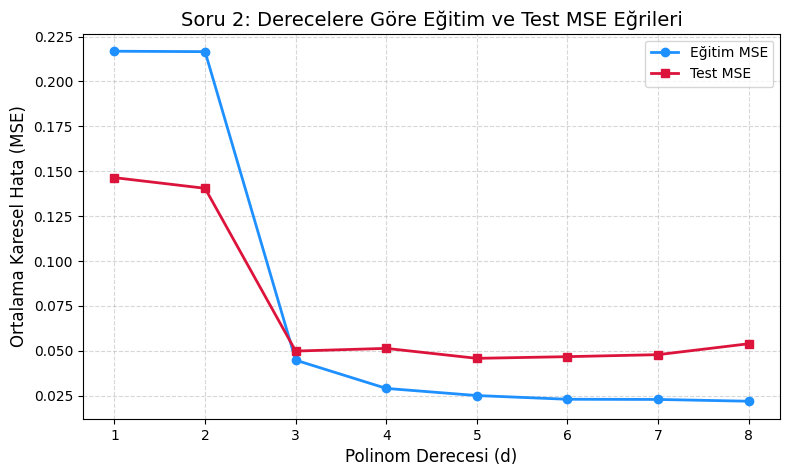

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(degrees, train_mse_list, marker='o', color='dodgerblue', linewidth=2, label='Eğitim MSE')
plt.plot(degrees, test_mse_list, marker='s', color='crimson', linewidth=2, label='Test MSE')
plt.xlabel('Polinom Derecesi (d)', fontsize=12)
plt.ylabel('Ortalama Karesel Hata (MSE)', fontsize=12)
plt.title('Soru 2: Derecelere Göre Eğitim ve Test MSE Eğrileri', fontsize=14)
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Soru 3: Model Seçimi ve GerekçelendirmeTabloyu ve test MSE eğrisini incelediğimizde:Derece 1 ve 2'de hata oldukça yüksek (underfitting - yetersiz öğrenme durumu var, model verideki eğrisel yapıyı yakalayamıyor).Derece 3 ve 5 civarında Test MSE minimum seviyelere iniyor. Özellikle Derece 5, test setindeki en düşük hatayı (0.045744) veriyor.   Derece 6, 7 ve 8'e doğru giderken eğitim hatası düşmeye devam etse de test hatası tekrar dalgalanmaya ve artmaya başlıyor (overfitting - aşırı öğrenme belirtisi).Seçimimiz: Bu analiz doğrultusunda en ideal model olarak Derece 5'i (veya gerekçesini açıklayarak Derece 3'ü) seçebiliriz. Derece 5, hem karmaşıklığı aşırı artırmadan verideki ana eğriyi modelleyebildiği hem de test verisi üzerinde en iyi genellemeyi (0.0457% hata ile) yaptığı için en mantıklı tercihtir. 

4.soru

In [10]:
selected_d = 5
degrees_to_compare = [selected_d - 1, selected_d, selected_d + 1] # 4, 5, 6

plt.figure(figsize=(12, 4))

<Figure size 1200x400 with 0 Axes>

<Figure size 1200x400 with 0 Axes>

In [11]:
for i, d in enumerate(degrees_to_compare):
    X_train_d = create_vander_matrix(x_train, d)
    beta_d = np.linalg.inv(X_train_d.T @ X_train_d) @ X_train_d.T @ y_train
    
    y_train_pred_d = X_train_d @ beta_d
    residuals = y_train - y_train_pred_d

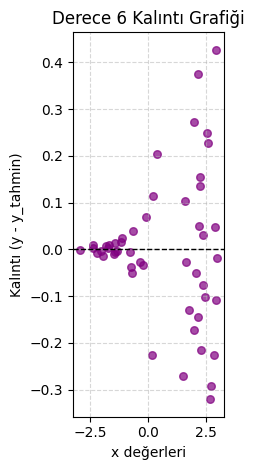

In [14]:
plt.subplot(1, 3, i + 1)
plt.scatter(x_train, residuals, color='purple', alpha=0.7, s=30)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlabel('x değerleri', fontsize=10)
plt.ylabel('Kalıntı (y - y_tahmin)', fontsize=10)
plt.title(f'Derece {d} Kalıntı Grafiği', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

5.soru

In [18]:
log_y_train = np.log(y_train)
log_y_test = np.log(y_test)

log_train_mse_list = []
log_test_mse_list = []
log_models_beta = {}

In [19]:
for d in degrees:
    X_train = create_vander_matrix(x_train, d)
    X_test = create_vander_matrix(x_test, d)
    
    beta_log = np.linalg.inv(X_train.T @ X_train) @ X_train.T @ log_y_train
    log_models_beta[d] = beta_log
    
    y_train_pred_log = np.exp(X_train @ beta_log)
    y_test_pred_log = np.exp(X_test @ beta_log)
    
    train_mse_log = np.mean((y_train - y_train_pred_log) ** 2)
    test_mse_log = np.mean((y_test - y_test_pred_log) ** 2)
    
    log_train_mse_list.append(train_mse_log)
    log_test_mse_list.append(test_mse_log)

In [21]:
results_log_df = pd.DataFrame({
    'Derece (d)': list(degrees),
    'Eğitim MSE (ln(y))': log_train_mse_list,
    'Test MSE (ln(y))': log_test_mse_list
})

In [22]:
print("--- ln(y) Dönüşümlü Model MSE Tablosu (Orijinal Ölçekte) ---")
display(results_log_df)

--- ln(y) Dönüşümlü Model MSE Tablosu (Orijinal Ölçekte) ---


,Derece (d),Eğitim MSE (ln(y)),Test MSE (ln(y))
0,1,1.781778,1.542448
1,2,0.025912,0.051277
2,3,0.027124,0.059895
3,4,0.023846,0.046887
4,5,0.023508,0.045978
5,6,0.023645,0.047341
6,7,0.024262,0.045288
7,8,0.021447,0.051787


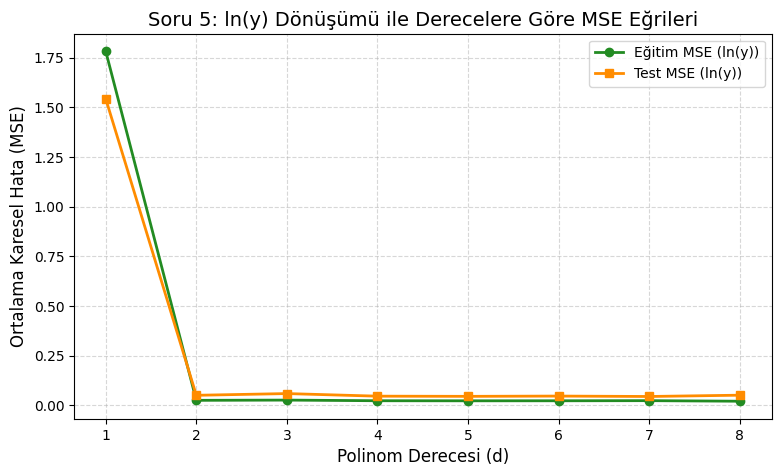

In [25]:
plt.figure(figsize=(9, 5))
plt.plot(degrees, log_train_mse_list, marker='o', color='forestgreen', linewidth=2, label='Eğitim MSE (ln(y))')
plt.plot(degrees, log_test_mse_list, marker='s', color='darkorange', linewidth=2, label='Test MSE (ln(y))')
plt.xlabel('Polinom Derecesi (d)', fontsize=12)
plt.ylabel('Ortalama Karesel Hata (MSE)', fontsize=12)
plt.title('Soru 5: ln(y) Dönüşümü ile Derecelere Göre MSE Eğrileri', fontsize=14)
plt.xticks(degrees)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

6.soru

In [26]:
x_dense = np.linspace(-4, 4, 300)

best_d_y = 5 
best_d_log = 5

In [35]:
X_dense_y = create_vander_matrix(x_dense, best_d_y)
X_train_y = create_vander_matrix(x_train, best_d_y)
beta_y = np.linalg.inv(X_train_y.T @ X_train_y) @ X_train_y.T @ y_train
y_pred_dense = X_dense_y @ beta_y

In [36]:
X_dense_log = create_vander_matrix(x_dense, best_d_log)
X_train_log = create_vander_matrix(x_train, best_d_log)
beta_log_fixed = np.linalg.inv(X_train_log.T @ X_train_log) @ X_train_log.T @ log_y_train
y_pred_log_dense = np.exp(X_dense_log @ beta_log_fixed)

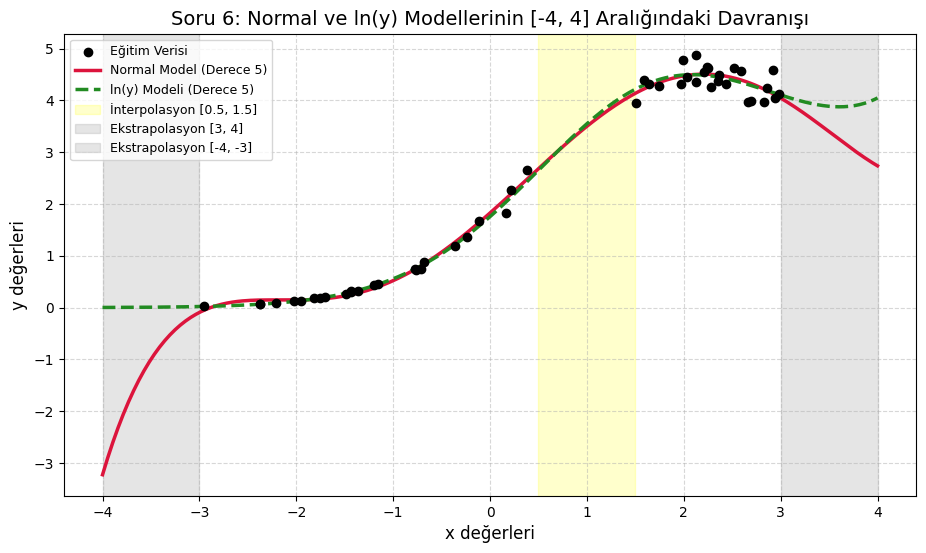

In [42]:
plt.figure(figsize=(11, 6))
plt.scatter(x_train, y_train, color='black', label='Eğitim Verisi', zorder=5)
plt.plot(x_dense, y_pred_dense, color='crimson', linewidth=2.5, label=f'Normal Model (Derece {best_d_y})')
plt.plot(x_dense, y_pred_log_dense, color='forestgreen', linewidth=2.5, linestyle='--', label=f'ln(y) Modeli (Derece {best_d_log})')
plt.axvspan(0.5, 1.5, color='yellow', alpha=0.2, label='İnterpolasyon [0.5, 1.5]')
plt.axvspan(3.0, 4.0, color='gray', alpha=0.2, label='Ekstrapolasyon [3, 4]')
plt.axvspan(-4.0, -3.0, color='gray', alpha=0.2, label='Ekstrapolasyon [-4, -3]')
plt.xlabel('x değerleri', fontsize=12)
plt.ylabel('y değerleri', fontsize=12)
plt.title('Soru 6: Normal ve ln(y) Modellerinin [-4, 4] Aralığındaki Davranışı', fontsize=14)
plt.legend(loc='upper left', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

7.soru

In [43]:
d_gd = 5
X_train_gd = create_vander_matrix(x_train, d_gd)

m, n = X_train_gd.shape
theta = np.zeros(n)

learning_rate = 0.00001
epochs = 5000
loss_history = []

In [44]:
for epoch in range(epochs):
    predictions = X_train_gd @ theta
    error = predictions - y_train
    loss = np.mean(error ** 2)
    loss_history.append(loss)
    
    gradient = (2/m) * (X_train_gd.T @ error)
    
    theta = theta - learning_rate * gradient

print("Gradyan Düşümü ile Bulunan Katsayılar (Theta):")
print(theta)

Gradyan Düşümü ile Bulunan Katsayılar (Theta):
[ 0.0887962   0.09053512  0.15953718  0.25248388  0.02495953 -0.02189107]


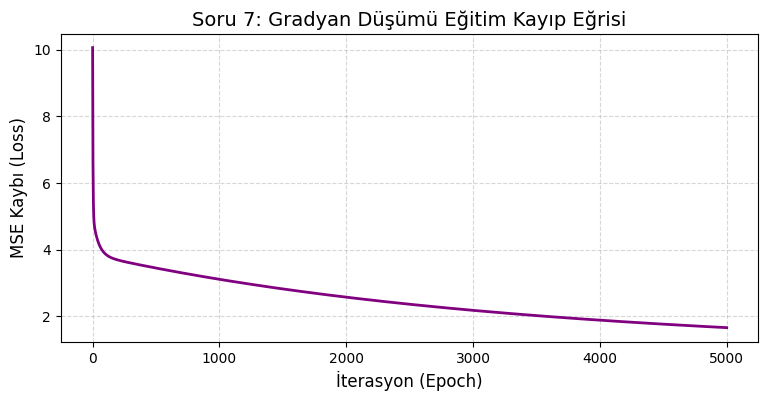

In [45]:
plt.figure(figsize=(9, 4))
plt.plot(loss_history, color='purple', linewidth=2)
plt.xlabel('İterasyon (Epoch)', fontsize=12)
plt.ylabel('MSE Kaybı (Loss)', fontsize=12)
plt.title('Soru 7: Gradyan Düşümü Eğitim Kayıp Eğrisi', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

8.soru

In [46]:
tahmin_x_df = pd.read_csv('tahmin_x.csv')
x_pred_new = tahmin_x_df.iloc[:, 0].values

X_pred_matrix = create_vander_matrix(x_pred_new, best_d_y)

y_predicted_values = X_pred_matrix @ beta_y

sonuc_df = pd.DataFrame({
    'x': x_pred_new,
    'tahmin_y': y_predicted_values
})

sonuc_df.to_csv('tahmin_sonuc.csv', index=False)

print("--- Tahminler Başarıyla Üretildi ve 'tahmin_sonuc.csv' Olarak Kaydedildi! ---")
print(sonuc_df.head(10))

--- Tahminler Başarıyla Üretildi ve 'tahmin_sonuc.csv' Olarak Kaydedildi! ---
    x    tahmin_y
0   1    3.500493
1   2    4.474727
2   3    4.045718
3   4    2.736630
4   5    3.161339
5   6   10.888296
6   7   35.304403
7   8   90.478880
8   9  196.027136
9  10  377.974636


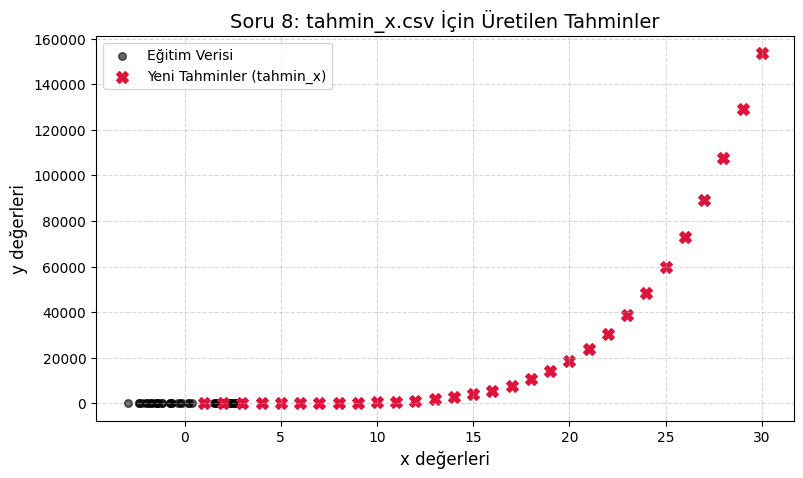

In [47]:
plt.figure(figsize=(9, 5))
plt.scatter(x_train, y_train, color='black', label='Eğitim Verisi', alpha=0.6, s=30)
plt.scatter(x_pred_new, y_predicted_values, color='crimson', marker='X', s=70, label='Yeni Tahminler (tahmin_x)')
plt.xlabel('x değerleri', fontsize=12)
plt.ylabel('y değerleri', fontsize=12)
plt.title('Soru 8: tahmin_x.csv İçin Üretilen Tahminler', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()